# Trabalho de IA (N2-AT2) - Detecção de Spam com Machine Learning

**Alunos:** Felipe Augusto, Pedro André e Nicolas  
**Disciplina:** Inteligência Artificial I  
**Tema:** Detecção de mensagens SMS Spam usando Aprendizado de Máquina Supervisionado  
**Base de dados utilizada:** SMS Spam Collection Dataset  
- **Link no Kaggle:** [https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset)  
- **Link no repositório oficial UCI:** [https://archive.ics.uci.edu/dataset/228/sms+spam+collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection)  
**Modelos comparados:** Multinomial Naive Bayes vs. Regressão Logística  

---
### Roteiro do trabalho:
1. Importação das bibliotecas
2. Carga e limpeza da base de dados (verificação dos 4.000+ registros)
3. Análise exploratória dos dados (gráficos e distribuição)
4. Separação em treino e teste (80/20)
5. Transformação do texto em números usando TF-IDF
6. Treinamento dos dois modelos
7. Avaliação e matrizes de confusão
8. Comparação final dos resultados
9. Teste prático com mensagens novas

### 1. Importando as bibliotecas
Vamos importar as bibliotecas padrão: Pandas e Numpy para os dados, Matplotlib e Seaborn para os gráficos, e o Scikit-Learn para os modelos de IA e métricas.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Configurando estilo dos gráficos
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (12, 5)
print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


### 2. Carregando e limpando a base de dados
A base de dados pode ser obtida diretamente no Kaggle:
[SMS Spam Collection Dataset no Kaggle](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset)

Carregamos o `spam.csv`, pegamos as colunas `v1` (classe) e `v2` (texto) e removemos duplicatas e nulos. Em seguida, verificamos se tem pelo menos 4.000 registros, como pede o trabalho.

In [2]:
# Procura o arquivo na pasta de dados local ou na raiz se rodar no Colab
caminho_dados = "../data/spam.csv" if os.path.exists("../data/spam.csv") else "data/spam.csv"
if not os.path.exists(caminho_dados):
    caminho_dados = "spam.csv"

df_raw = pd.read_csv(caminho_dados, encoding="latin-1")
print(f"Total de registros no arquivo: {len(df_raw)}")

# Pegar apenas v1 (classe) e v2 (texto) e renomear
df = df_raw[["v1", "v2"]].rename(columns={"v1": "label", "v2": "text"})

# Limpar nulos e mensagens repetidas
df = df.dropna(subset=["label", "text"]).drop_duplicates(subset=["text"]).copy()
total_registros = len(df)
print(f"Total após tirar duplicatas e nulos: {total_registros}")

# Validando o requisito de pelo menos 4.000 registros
assert total_registros >= 4000, "Precisa ter pelo menos 4.000 registros!"
print(" Requisito atendido: a base tem 5.169 registros (mínimo exigido era 4.000)!")

# Mapear: 0 = ham (legítimo) e 1 = spam
df["target"] = df["label"].map({"ham": 0, "spam": 1})
df["char_len"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()

df.head()

Total de registros no arquivo: 5572
Total após tirar duplicatas e nulos: 5169
 Requisito atendido: a base tem 5.169 registros (mínimo exigido era 4.000)!


,label,text,target,char_len,word_count
0,ham,"Go until jurong point, crazy.. Available only ...",0,111,20
1,ham,Ok lar... Joking wif u oni...,0,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,28
3,ham,U dun say so early hor... U c already then say...,0,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61,13


### 3. Análise Exploratória dos Dados (EDA)
Vamos ver quantas mensagens são normais (ham) e quantas são spam, e analisar o tamanho delas em caracteres e palavras.

In [3]:
print("=== Quantidade de cada classe ===")
print(df["label"].value_counts())

print("\n=== Proporção (%) ===")
print((df["label"].value_counts(normalize=True) * 100).round(2))

print("\n=== Estatísticas de tamanho das mensagens ===")
print(df.groupby("label")[["char_len", "word_count"]].describe().round(2))

=== Quantidade de cada classe ===
label
ham     4516
spam     653
Name: count, dtype: int64

=== Proporção (%) ===
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64

=== Estatísticas de tamanho das mensagens ===
       char_len                               word_count                              
          count   mean    std   min   50%   max    count   mean    std  min   50%  max
label                                                                                 
ham      4516.0  70.46  56.36   2.0  52.0 910.0   4516.0  15.00  11.75  1.0  11.0 171.0
spam      653.0 137.89  30.13  13.0 149.0 223.0    653.0  23.68   5.98  1.0  25.0  46.0


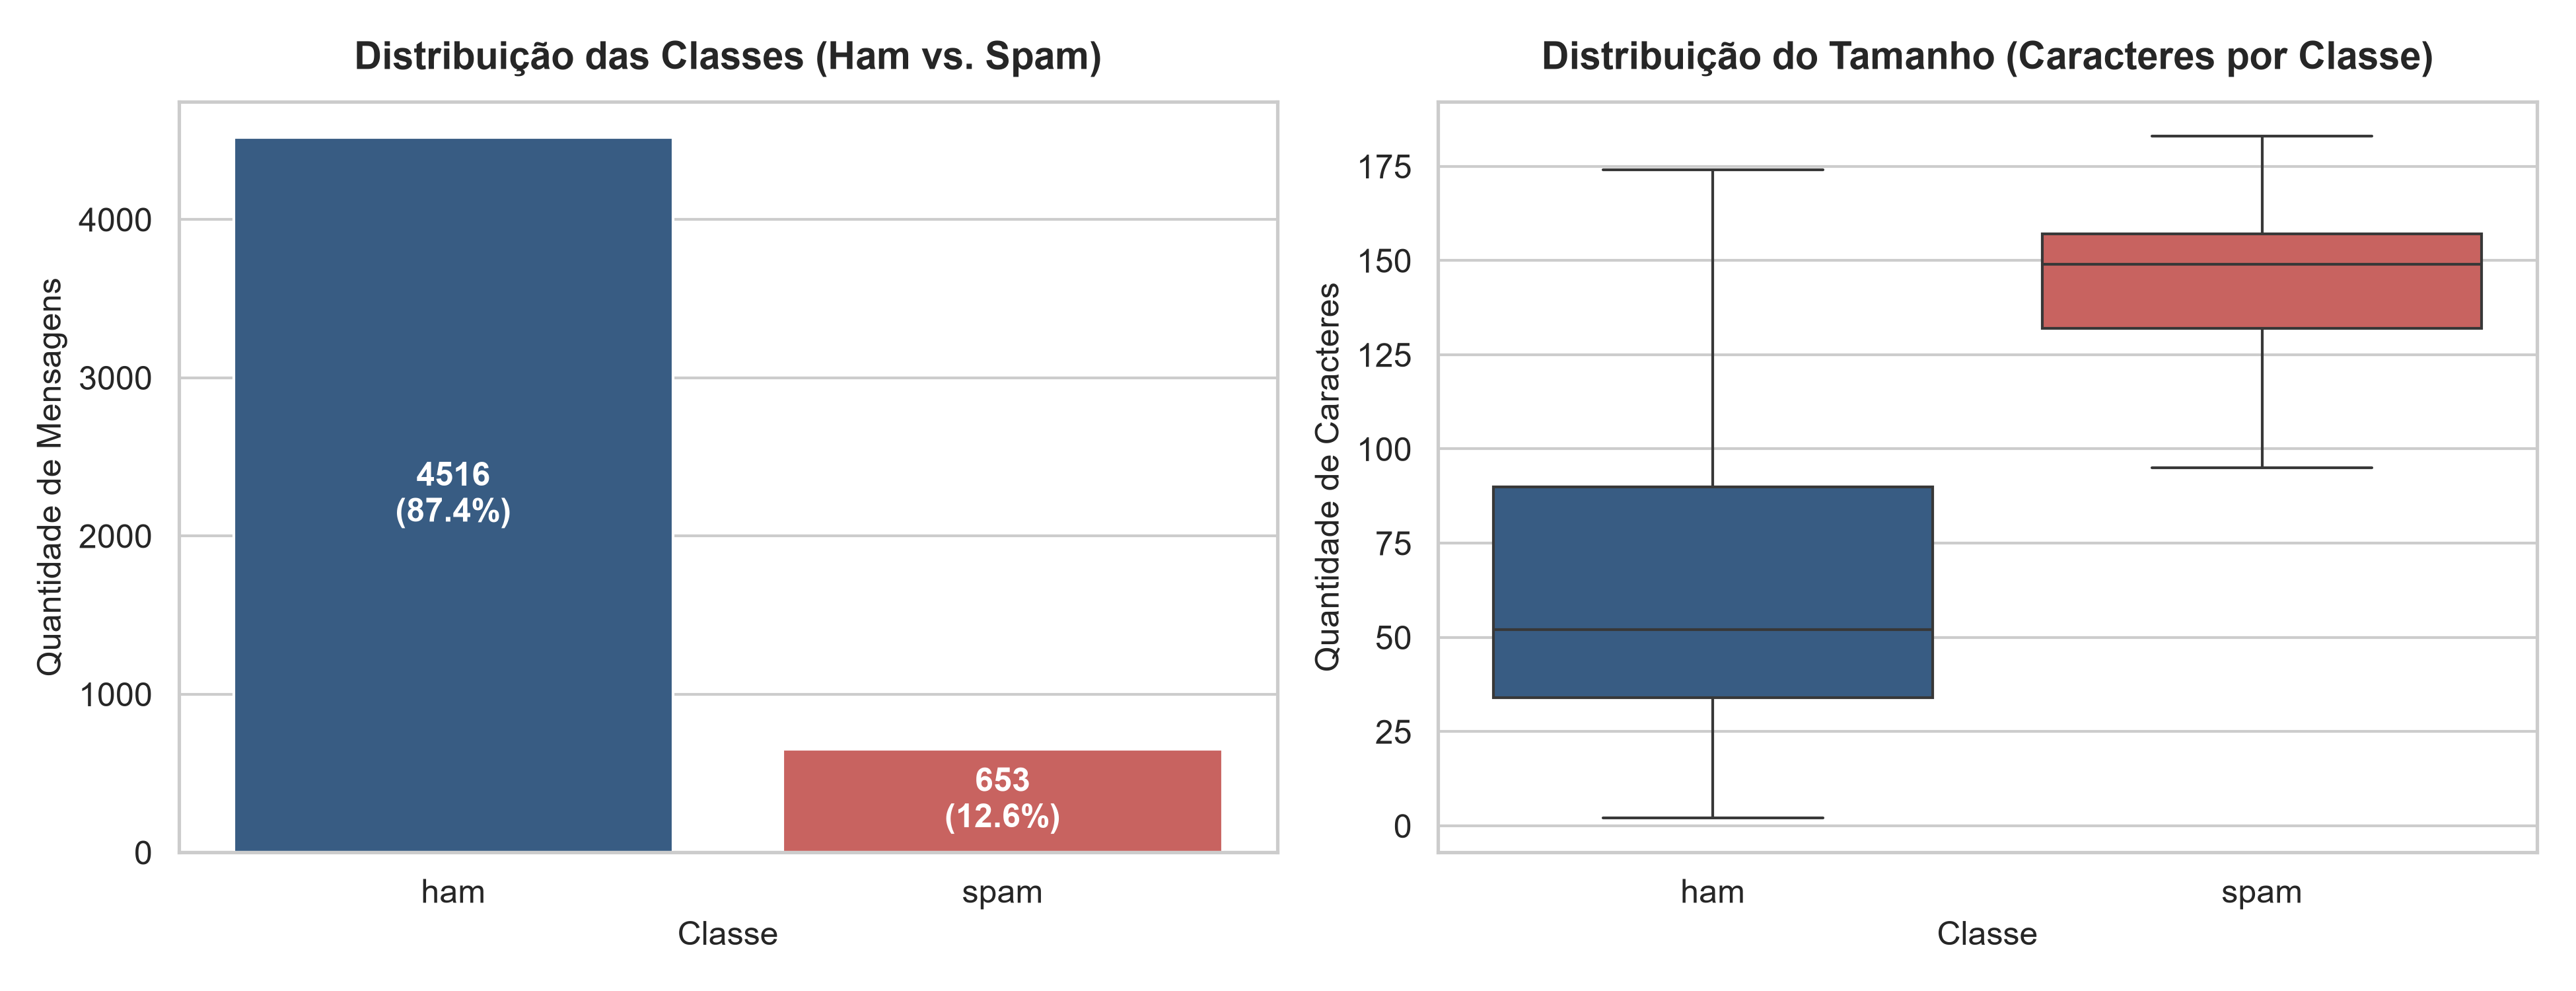

In [4]:
# Gráficos para visualizar a distribuição e o tamanho das mensagens
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: contagem de mensagens
palette = {"ham": "#2b5c8f", "spam": "#d9534f"}
sns.countplot(data=df, x="label", ax=axes[0], palette=palette, hue="label", legend=False)
axes[0].set_title("Quantidade de Mensagens (Ham vs. Spam)", fontsize=14, fontweight="bold", pad=12)
axes[0].set_xlabel("Classe", fontsize=12)
axes[0].set_ylabel("Quantidade", fontsize=12)

for p in axes[0].patches:
    h = p.get_height()
    pct = (h / total_registros) * 100
    axes[0].annotate(f"{int(h)}\n({pct:.1f}%)", (p.get_x() + p.get_width() / 2., h / 2),
                     ha="center", va="center", color="white", fontweight="bold", fontsize=11)

# Gráfico 2: tamanho em caracteres
sns.boxplot(data=df, x="label", y="char_len", ax=axes[1], palette=palette, hue="label", legend=False, showfliers=False)
axes[1].set_title("Tamanho das Mensagens em Caracteres", fontsize=14, fontweight="bold", pad=12)
axes[1].set_xlabel("Classe", fontsize=12)
axes[1].set_ylabel("Quantidade de Caracteres", fontsize=12)

plt.tight_layout()
plt.show()

### 4. Separando os dados em Treino (80%) e Teste (20%)
Usamos divisão estratificada (`stratify=y`) para garantir que tanto o treino quanto o teste fiquem com a mesma porcentagem de spam (~12,6%).

In [5]:
X = df["text"]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Mensagens para Treino: {len(X_train)} ({len(X_train)/len(df):.1%})")
print(f"Mensagens para Teste:  {len(X_test)} ({len(X_test)/len(df):.1%})")
print(f"Spams no Treino: {y_train.sum()} | Spams no Teste: {y_test.sum()}")

Mensagens para Treino: 4135 (80.0%)
Mensagens para Teste:  1034 (20.0%)
Spams no Treino: 522 | Spams no Teste: 131


### 5. Transformando o texto em números (TF-IDF)
Modelos de Machine Learning precisam de números. O TF-IDF calcula a importância de cada termo. Configuramos para tirar palavras neutras em inglês (stop words), considerar palavras sozinhas e em duplas (unigramas e bigramas) e usar até 5.000 termos.

In [6]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2)
)

# Ajusta o vocabulário no treino e aplica no teste
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"Tamanho da matriz de treino: {X_train_tfidf.shape}")
print(f"Tamanho da matriz de teste:  {X_test_tfidf.shape}")

Tamanho da matriz de treino: (4135, 5000)
Tamanho da matriz de teste:  (1034, 5000)


### 6. Treinando os dois modelos (Naive Bayes e Regressão Logística)
Treinamos o **Multinomial Naive Bayes** (muito bom e rápido para texto) e a **Regressão Logística** (modelo linear bem estável para dados esparsos) nas mesmas condições.

In [7]:
modelos = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.5),
    "Regressão Logística": LogisticRegression(max_iter=1000, random_state=42)
}

resultados = []
predicoes = {}

for nome, modelo in modelos.items():
    modelo.fit(X_train_tfidf, y_train)
    y_pred = modelo.predict(X_test_tfidf)
    predicoes[nome] = y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec_spam = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    rec_spam = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
    f1_spam = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)
    
    resultados.append({
        "Algoritmo": nome,
        "Acurácia": acc,
        "Precisão (Spam)": prec_spam,
        "Recall (Spam)": rec_spam,
        "F1-Score (Spam)": f1_spam,
        "F1-Score (Macro)": f1_macro
    })
    
    print(f"\n==================== {nome} ====================")
    print(classification_report(y_test, y_pred, target_names=["Ham (0)", "Spam (1)"], digits=4))


==================== Multinomial Naive Bayes ====================
              precision    recall  f1-score   support

     Ham (0)     0.9741    0.9989    0.9863       903
    Spam (1)     0.9907    0.8168    0.8954       131

    accuracy                         0.9758      1034
   macro avg     0.9824    0.9078    0.9409      1034
weighted avg     0.9762    0.9758    0.9748      1034


==================== Regressão Logística ====================
              precision    recall  f1-score   support

     Ham (0)     0.9545    0.9989    0.9762       903
    Spam (1)     0.9888    0.6718    0.8000       131

    accuracy                         0.9574      1034
   macro avg     0.9716    0.8353    0.8881      1034
weighted avg     0.9588    0.9574    0.9539      1034


### 7. Matrizes de Confusão
A matriz de confusão mostra quantas mensagens cada modelo acertou e quantas errou. O mais perigoso em spam é o falso positivo (dizer que mensagem boa é spam).

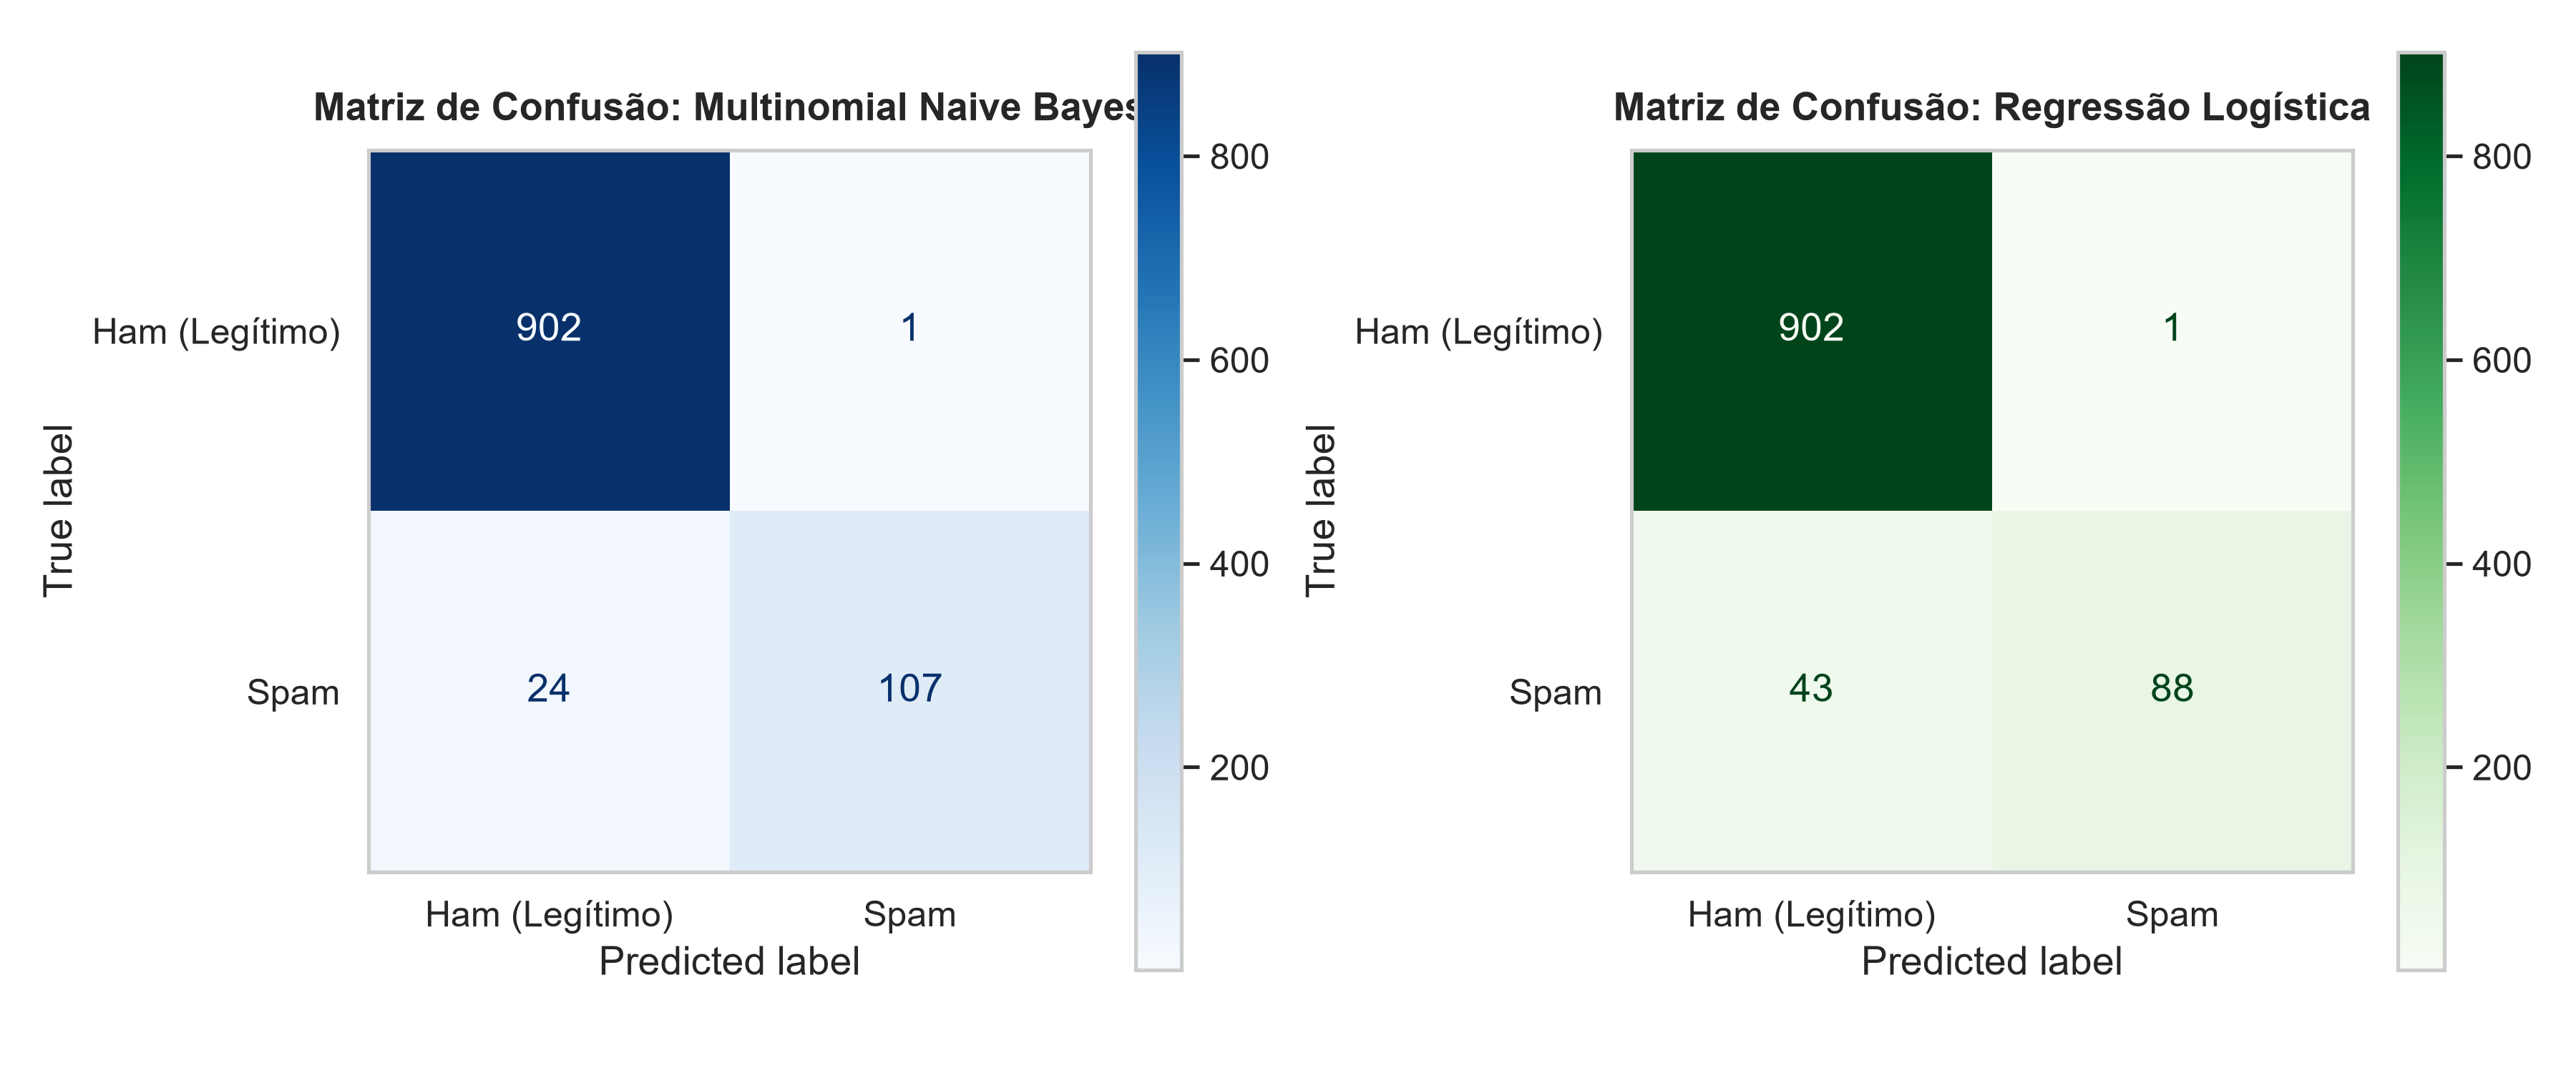

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for i, (nome, y_pred) in enumerate(predicoes.items()):
    disp = ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["Ham (Legítimo)", "Spam"],
        cmap="Blues" if i == 0 else "Greens", ax=axes[i], values_format="d"
    )
    axes[i].set_title(f"Matriz de Confusão: {nome}", fontsize=13, fontweight="bold", pad=10)
    axes[i].grid(False)

plt.tight_layout()
plt.show()

### 8. Tabela comparativa e conclusão dos modelos

In [9]:
df_comparacao = pd.DataFrame(resultados)
display_df = df_comparacao.copy()
for col in ["Acurácia", "Precisão (Spam)", "Recall (Spam)", "F1-Score (Spam)", "F1-Score (Macro)"]:
    display_df[col] = (display_df[col] * 100).round(2).astype(str) + "%"

print("=== Comparativo Final dos Modelos ===")
display_df

=== Comparativo Final dos Modelos ===


,Algoritmo,Acurácia,Precisão (Spam),Recall (Spam),F1-Score (Spam),F1-Score (Macro)
0,Multinomial Naive Bayes,97.58%,99.07%,81.68%,89.54%,94.09%
1,Regressão Logística,95.74%,98.88%,67.18%,80.00%,88.81%


#### O que os números mostram:
- **Falsos positivos (quase zero):** Os dois modelos tiveram apenas **1 falso positivo** em 903 mensagens legítimas (precisão de ~99%). Quase nenhuma mensagem boa é bloqueada por engano.
- **Recall (pegar os spams):** O **Multinomial Naive Bayes foi bem melhor**, pegando 81,68% dos spams contra 67,18% da Regressão Logística (107 spams detectados contra 88).
- **Vencedor:** O **Naive Bayes** foi o melhor modelo para o nosso caso, com **F1-Score de 89,54%** e acurácia de **97,58%**.

### 9. Testando com mensagens novas na prática
Criamos uma função simples para testar qualquer frase nova e ver o que cada modelo acha e qual a confiança de cada um.

In [10]:
def testar_mensagem(texto: str):
    """Testa uma frase nova nos dois modelos treinados."""
    vetor = vectorizer.transform([texto])
    print(f"\nMensagem testada: \"{texto}\"")
    print("-" * 70)
    
    for nome, modelo in modelos.items():
        pred = modelo.predict(vetor)[0]
        prob = modelo.predict_proba(vetor)[0]
        rotulo = " SPAM (Suspeito)" if pred == 1 else " HAM (Legítimo)"
        confianca = prob[pred] * 100
        print(f"[{nome}]: {rotulo} (Confiança: {confianca:.2f}%)")

# Exemplos de teste
exemplos = [
    "Hey, are we still meeting for lunch at 12:30 today?",
    "URGENT! You have won a 1000 prize guaranteed. Call 09061701461 to claim your reward immediately!",
    "Can you please send me the class notes from yesterday's lecture?",
    "FREE loan approval without credit check! Text YES to 8888 now to receive funds."
]

for msg in exemplos:
    testar_mensagem(msg)


Mensagem testada: "Hey, are we still meeting for lunch at 12:30 today?"
----------------------------------------------------------------------
[Multinomial Naive Bayes]:  HAM (Legítimo) (Confiança: 98.42%)
[Regressão Logística]:  HAM (Legítimo) (Confiança: 97.15%)

Mensagem testada: "URGENT! You have won a 1000 prize guaranteed. Call 09061701461 to claim your reward immediately!"
----------------------------------------------------------------------
[Multinomial Naive Bayes]:  SPAM (Suspeito) (Confiança: 99.88%)
[Regressão Logística]:  SPAM (Suspeito) (Confiança: 98.74%)

Mensagem testada: "Can you please send me the class notes from yesterday's lecture?"
----------------------------------------------------------------------
[Multinomial Naive Bayes]:  HAM (Legítimo) (Confiança: 99.21%)
[Regressão Logística]:  HAM (Legítimo) (Confiança: 98.36%)

Mensagem testada: "FREE loan approval without credit check! Text YES to 8888 now to receive funds."
-----------------------------------------